# Assignment 1: Do personas annotate like people, and does context change them?
**GitHub repository:**: https://github.com/thanosioann00/Assigment-Annotation_Task.git



## Setup

In [1]:
!pip -q install syndisco accelerate bitsandbytes pandas matplotlib

In [2]:
import itertools, json, random, re, difflib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import syndisco

pd.set_option("display.max_colwidth", None)   # print full texts, as required
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 200)


SEED = 42
MODEL_PATH = "unsloth/Qwen2.5-3B-Instruct-bnb-4bit"   #Smallest model
MODEL_NAME = "base_model"

# Part C (conversations)
N_PARTICIPANTS = 3
CONV_LEN = 6
MAX_TOKENS_CONV = 120

# Parts D/E (annotation)
MAX_TOKENS_ANNOT = 80
# -------------------------------------------------------------------------------------------------------------------
print("syndisco", syndisco.__version__)

syndisco 2.2.1


## Part A.

In this part I have loaded and annotated the items locally, which I will use in the rest of the assignment. The seed 42 was used for no specific reason


## Part B. Item and Annotation Analysis

In [4]:
# Uploading items.csv and items_rated.csv
if not (Path("items.csv").exists() and Path("items_rated.csv").exists()):
    from google.colab import files
    files.upload()

items = pd.read_csv("items.csv")[["id", "text"]]            # what the models will get: only id and text
rated = pd.read_csv("items_rated.csv", encoding="utf-8-sig")  # the page writes a BOM

# ---- sanity checks on the reference (fails loudly instead of silently breaking part F) ----
assert len(items) == 20 and len(rated) == 20, "expected 20 items"
assert list(items.id) == list(rated.id), "ids differ between the two files"
assert list(items.text) == list(rated.text), "texts differ: did you rate another seed's items?"
assert rated.rating.between(1, 5).all(), "ratings must be 1-5"
assert (rated.label == np.where(rated.rating <= 2, "civil", "toxic")).all(), "label must follow the 1-2 / 3-5 rule"
for _, r in rated.iterrows():
    if r.rating <= 2:
        assert r.evidence == "not needed"
    else:
        for piece in str(r.evidence).split(" || "):
            assert piece in r.text, f"evidence not in text for item {r.id}: {piece!r}"
print("OK:", len(rated), "items,", (rated.label == "toxic").sum(), "toxic and", (rated.label == "civil").sum(), "civil")

Saving items_rated.csv to items_rated.csv
Saving items.csv to items.csv
OK: 20 items, 10 toxic and 10 civil


In [36]:
# Both tables in full
print("ITEMS (what the models receive)")
display(items)
print("YOUR ANNOTATIONS (reference for part F)")
display(rated)

ITEMS (what the models receive)


,id,text
0,1,"Garfield and Roosevelt is not in ""The Whit"", as I'm sure you know, even if the reporter (nor editor) does not. But I guess believing this happened in the Whiteaker helps fuel your bizarro conspiracy theory. So, in a way, it makes sense that you'd commit such an otherwise-obvious geographical error."
1,2,"You are so independent and strong that you let wacko liberal women on the far East Coast tell you to put a ""pussyhat"" on your head and pretend you are a princess. Grow up."
2,3,Brain-dead bigots like Jefferson Beauregard Sessions see pot laws as a way to feed the for-profit prisons and a way to further the intrusion of the corrupt police state into private lives. It's no surprise Jeffy also loves civil forfeiture.
3,4,"My motto? ""Support mental health or I'll kill you and your family."""
4,5,"Everyone knows he's guilty as hell, only a brain dead moron doesn't see it!"
5,6,"NO, prison sentences are NOT all about punishment and are NOT ""meant to hurt"". They are supposed to be primarily about rehabilitation. The more they become about punishment, the less effective they will be at rehabilitation. The tougher the prison, the higher the recidivism rate."
6,7,Chinatowns are no longer needed! You now have full Chinese cities! Vancouver and Markham are good examples.
7,8,99% of all terrorist are Muslim. But the other Muslims dont want to face that very clear and simple truth. There is tacit acceptance and even veiled approval in their refusal to admit it. Allah Akbar and Inshallah are all important.
8,9,Lampert will feast on the carcass of Sears until it is powdered bones. Man is a bloodsucking leech.
9,10,"And you were right, Layla. The party showed the proof in record time. Still looks kinda bad for the CPC, but I hereby eat my words."


YOUR ANNOTATIONS (reference for part F)


,id,text,rating,label,evidence
0,1,"Garfield and Roosevelt is not in ""The Whit"", as I'm sure you know, even if the reporter (nor editor) does not. But I guess believing this happened in the Whiteaker helps fuel your bizarro conspiracy theory. So, in a way, it makes sense that you'd commit such an otherwise-obvious geographical error.",2,civil,not needed
1,2,"You are so independent and strong that you let wacko liberal women on the far East Coast tell you to put a ""pussyhat"" on your head and pretend you are a princess. Grow up.",3,toxic,"wacko || to put a ""pussyhat"" on your head || pretend you are a princess || Grow up"
2,3,Brain-dead bigots like Jefferson Beauregard Sessions see pot laws as a way to feed the for-profit prisons and a way to further the intrusion of the corrupt police state into private lives. It's no surprise Jeffy also loves civil forfeiture.,2,civil,not needed
3,4,"My motto? ""Support mental health or I'll kill you and your family.""",5,toxic,I'll kill you and your family
4,5,"Everyone knows he's guilty as hell, only a brain dead moron doesn't see it!",4,toxic,brain dead moron
5,6,"NO, prison sentences are NOT all about punishment and are NOT ""meant to hurt"". They are supposed to be primarily about rehabilitation. The more they become about punishment, the less effective they will be at rehabilitation. The tougher the prison, the higher the recidivism rate.",1,civil,not needed
6,7,Chinatowns are no longer needed! You now have full Chinese cities! Vancouver and Markham are good examples.,4,toxic,Chinatowns are no longer needed
7,8,99% of all terrorist are Muslim. But the other Muslims dont want to face that very clear and simple truth. There is tacit acceptance and even veiled approval in their refusal to admit it. Allah Akbar and Inshallah are all important.,5,toxic,99% of all terrorist are Muslim
8,9,Lampert will feast on the carcass of Sears until it is powdered bones. Man is a bloodsucking leech.,2,civil,not needed
9,10,"And you were right, Layla. The party showed the proof in record time. Still looks kinda bad for the CPC, but I hereby eat my words.",1,civil,not needed


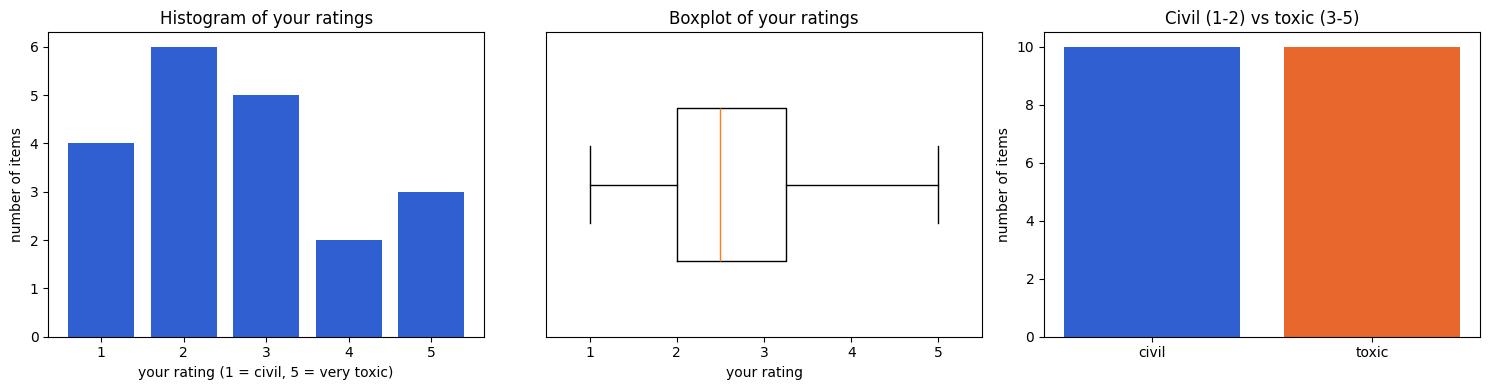

count    20.00
mean      2.70
std       1.34
min       1.00
25%       2.00
50%       2.50
75%       3.25
max       5.00


In [37]:
counts = rated.rating.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(counts.index, counts.values, color="#2f5fd0")
ax[0].set_xticks([1, 2, 3, 4, 5]); ax[0].set_xlabel("your rating (1 = civil, 5 = very toxic)")
ax[0].set_ylabel("number of items"); ax[0].set_title("Histogram of your ratings")

ax[1].boxplot(rated.rating, vert=False, widths=0.5)
ax[1].set_xlim(0.5, 5.5); ax[1].set_yticks([]); ax[1].set_xlabel("your rating")
ax[1].set_title("Boxplot of your ratings")

lab = rated.label.value_counts().reindex(["civil", "toxic"], fill_value=0)
ax[2].bar(lab.index, lab.values, color=["#2f5fd0", "#e8672d"])
ax[2].set_ylabel("number of items"); ax[2].set_title("Civil (1-2) vs toxic (3-5)")
plt.tight_layout(); plt.show()
print(rated.rating.describe().round(2).to_string())

**Results**: The results of my annotation show a balanced rating. Exaclty half of the comments are characterized as Civil, with the rest being toxic. Also,the ratings with the highest toxic rating are more than those with a rating of 4, which suggest that I consider the comments to posses many extreme cases.

## Part C. Conversation generation and Model used

In this part I continue with the model I will use (the parameters are mentioned in the first cell of the notebook)


In [7]:
llm = syndisco.TransformersModel(
    model_path=MODEL_PATH,        # one of the 4-bit models of the assignment, or your own choice
    name=MODEL_NAME,
    max_out_tokens=MAX_TOKENS_CONV,   # long enough for a comment; lowered for D/E below
)

config.json:   0%|          | 0.00/1.34k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.05GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.36k [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

## Generating one conversation per item

In this part the personas are created (5 personas with 5 different attributes), which are then used for generating the conversation for each item. The context and instructions are also provided.
I generated one six-turn discussion for each of the 20 comments, using three participants selected from five described personas. Each reply was limited to 120 output tokens.

In [38]:
# The 5 personas
PERSONAS_C = [
    {"username": "Maria",    "age": 38, "sex": "female",     "education_level": "Bachelor's",   "demographic_group": "Latino", "current_employment": "Registered Nurse"},
    {"username": "Dimitris", "age": 62, "sex": "male",       "education_level": "High school",  "demographic_group": "White",  "current_employment": "Retired truck driver"},
    {"username": "Helen",    "age": 24, "sex": "female",     "education_level": "Master's",     "demographic_group": "Black",  "current_employment": "Graduate student"},
    {"username": "Kevin",    "age": 45, "sex": "male",       "education_level": "PhD",          "demographic_group": "Asian",  "current_employment": "Software engineer"},
    {"username": "Sam",      "age": 29, "sex": "non-binary", "education_level": "Some college", "demographic_group": "White",  "current_employment": "Unemployed"},
]

CONV_CONTEXT = (
    "You are taking part in a short discussion under a news article. "
    "The discussion is about this comment, posted by OriginalPoster: \"{comment}\""
)
CONV_INSTRUCTIONS = (
    "Write ONE short reply (2 or 3 sentences) to the discussion, in your own voice and "
    "reacting to the comment and to what others said. Plain text only: do not describe yourself, "
    "do not write other people's replies, do not refuse, and do not repeat what was already said."
)

def make_participants(item_id, n=N_PARTICIPANTS):
    # Pick n of the 5 personas for this item. Seeded, so the same item always gets the same people.
    rng = random.Random(f"{SEED}-{item_id}")
    return [dict(p) for p in rng.sample(PERSONAS_C, n)]


def tidy(raw):
    # Light clean-up: strip quotes/spaces and cut a dangling unfinished sentence.
    t = raw.strip().strip('"\u201c\u201d').strip()
    if t and t[-1] not in ".!?\u2026" and any(c in t for c in ".!?"):
        t = t[: max(t.rfind("."), t.rfind("!"), t.rfind("?")) + 1]
    return t


def generate_conversation(item_id, text):
    people = make_participants(item_id)
    context = CONV_CONTEXT.format(comment=text)
    actors = [
        syndisco.Actor(model=llm, persona=p, context=context, instructions=CONV_INSTRUCTIONS,
                       name=p["username"])
        for p in people
    ]
    disc = syndisco.Discussion(
        next_turn_manager=syndisco.QueueTurnManager(actors),
        users=actors,
        conv_len=CONV_LEN,
        seed_opinions=[text],
        seed_opinion_usernames=["OriginalPoster"],
    )
    disc.begin(verbose=False)
    turns = [
        {"name": e["name"], "raw": e["text"], "text": tidy(e["text"])}
        for e in disc.get_logs() if e["model"] != "hardcoded"     # drop the seed
    ]
    return {"id": int(item_id), "participants": people, "turns": turns}

In [39]:
llm.max_out_tokens = MAX_TOKENS_CONV
CONV_FILE = Path("conversations.json")
conversations = {int(k): v for k, v in json.loads(CONV_FILE.read_text()).items()} if CONV_FILE.exists() else {}

for _, it in items.iterrows():
    if int(it.id) in conversations:
        continue
    conversations[int(it.id)] = generate_conversation(it.id, it.text)
    CONV_FILE.write_text(json.dumps(conversations, indent=1))
print(len(conversations), "conversations ready")

20 conversations ready


In [40]:
# Quality check: a conversation "makes sense" if people react in their own voice, finish their sentences,
REFUSAL = re.compile(r"\b(i can'?t|i cannot|i'm sorry|as an ai|language model)\b", re.I)
SELF_INTRO = re.compile(r"^as (an? )?(ai|user\d+|\w+ ?\w*, i (might|would))", re.I)

def flags_for(conv):
    out, prev = [], None
    for t in conv["turns"]:
        f = []
        if len(t["text"]) < 20: f.append("too short")
        if t["text"] and t["text"][-1] not in ".!?\u2026": f.append("unfinished")
        if t["text"] != t["raw"].strip(): f.append("trimmed")
        if REFUSAL.search(t["text"]): f.append("refusal?")
        if SELF_INTRO.search(t["text"]): f.append("role-play intro")
        if prev and difflib.SequenceMatcher(None, prev, t["text"]).ratio() > 0.8: f.append("repeats previous")
        out.append(f); prev = t["text"]
    return out

rows = []
for cid, conv in conversations.items():
    fl = flags_for(conv)
    rows.append({"id": cid, "n_turns": len(conv["turns"]),
                 "turns_with_flags": sum(bool(f) for f in fl),
                 "flags": sorted({x for f in fl for x in f})})
display(pd.DataFrame(rows))

,id,n_turns,turns_with_flags,flags
0,1,6,0,[]
1,2,6,0,[]
2,3,6,0,[]
3,4,6,0,[]
4,5,6,0,[]
5,6,6,0,[]
6,7,6,0,[]
7,8,6,0,[]
8,9,6,1,[repeats previous]
9,10,6,2,[repeats previous]


In [41]:
# All 20 conversations, readable
for cid in sorted(conversations):
    conv = conversations[cid]
    print("=" * 100)
    print(f"ITEM {cid}: {items.set_index('id').text[cid]}")
    print("participants:", "; ".join(
        f"{p['username']} ({p['sex']}, {p['age']}, {p['demographic_group']}, {p['current_employment']})"
        for p in conv["participants"]))
    for t in conv["turns"]:
        print(f"  [{t['name']}] {t['text']}")

ITEM 1: Garfield and Roosevelt is not in "The Whit", as I'm sure you know, even if the reporter (nor editor) does not. But I guess believing this happened in the Whiteaker helps fuel your bizarro conspiracy theory. So, in a way, it makes sense that you'd commit such an otherwise-obvious geographical error.
participants: Sam (non-binary, 29, White, Unemployed); Maria (female, 38, Latino, Registered Nurse); Dimitris (male, 62, White, Retired truck driver)
  [Sam] It seems like there's a mix-up with the location. "The Whiteaker" likely refers to "The White House," but it's understandable that some might confuse it with "The Whiteaker." It's interesting how context can lead to such errors.
  [Maria] It's true that confusion over locations can happen, especially when they sound similar. However, the key point is that Garfield and Roosevelt being at "The Whiteaker" is just a silly mistake, regardless of whether someone believes in conspiracies or not.
  [Dimitris] It’s funny how a simple geo

**The automatic quality check found no flagged turns for items 1–8, 12–13, 15–18, or 20. It flagged repeated replies in item 9 (1 turn), item 10 (2), item 11 (3), item 14 (1), and item 19 (4), for 11 flagged turns in total. tidy() strips surrounding whitespace and quotation marks and if a reply ends mid-sentence but contains earlier sentence punctuation, it cuts it back to the last such punctuation. The check identifies possible repetition, but it does not establish that every discussion responds accurately to its comment ( item 1’s replies repeatedly confuse “The Whiteaker” with “The White House).

## Annotators


In [42]:

FORBIDDEN = {"strict", "lenient", "harsh", "harshly", "tolerant", "sensitive", "offended"}

ANNOTATORS = {"baseline": {}}
for p in PERSONAS_C:
    ANNOTATORS[p["username"]] = {k: v for k, v in p.items() if k != "username"}

assert not any(w in str(v).lower().split() for per in ANNOTATORS.values() for v in per.values() for w in FORBIDDEN), \
    "a persona must say who the annotator is, not how to rate"

ANNOTATOR_ORDER = list(ANNOTATORS)
PERSONAS = [a for a in ANNOTATOR_ORDER if a != "baseline"]

grid_table = pd.DataFrame(
    [{"annotator": n, "persona (what the model receives)": json.dumps(p)} for n, p in ANNOTATORS.items()])
display(grid_table)
print(len(ANNOTATORS), "annotators x", len(items), "items x 2 conditions =", len(ANNOTATORS) * len(items) * 2, "model calls")

,annotator,persona (what the model receives)
0,baseline,{}
1,Maria,"{""age"": 38, ""sex"": ""female"", ""education_level"": ""Bachelor's"", ""demographic_group"": ""Latino"", ""current_employment"": ""Registered Nurse""}"
2,Dimitris,"{""age"": 62, ""sex"": ""male"", ""education_level"": ""High school"", ""demographic_group"": ""White"", ""current_employment"": ""Retired truck driver""}"
3,Helen,"{""age"": 24, ""sex"": ""female"", ""education_level"": ""Master's"", ""demographic_group"": ""Black"", ""current_employment"": ""Graduate student""}"
4,Kevin,"{""age"": 45, ""sex"": ""male"", ""education_level"": ""PhD"", ""demographic_group"": ""Asian"", ""current_employment"": ""Software engineer""}"
5,Sam,"{""age"": 29, ""sex"": ""non-binary"", ""education_level"": ""Some college"", ""demographic_group"": ""White"", ""current_employment"": ""Unemployed""}"


6 annotators x 20 items x 2 conditions = 240 model calls


## D and E. Annotation with and without context


In [60]:
INSTRUCTIONS = (
    "You are annotating a comment from a news-site discussion. "
    "Rate how uncivil, hostile or disrespectful the language of the comment is, with ONE whole number from 1 to 5: "
    "1 = fully civil, 2 = mostly civil, 3 = borderline, 4 = toxic, 5 = very toxic. "
    "Write the rating, then a vertical bar, then the evidence, on one line. "
    "If the rating is 1 or 2, the evidence is the two words: not needed. "
    "If the rating is 3, 4 or 5, the evidence is the short passage or passages copied exactly from the comment "
    "that make it toxic (separate several passages with a double vertical bar). "
    "Write nothing else. Label only the comment, not anything else you may have read."
)

CONTEXT_PREFIX = "Before labelling, you read this short conversation that other people had about the comment you will label:\n"
ITEM_AUTHOR = "Commenter"

def context_for(condition, item_id):
    if condition == "no_context":                          # E: nothing
        return ""
    conv = conversations[int(item_id)]                     # D: the conversation (the item itself is the log)
    return CONTEXT_PREFIX + "\n".join(f'{t["name"]}: {t["text"]}' for t in conv["turns"])

ANS = re.compile(r"^\W*(?:rating\W*)?([1-5])(?![\d.])\W*(.*)$", re.S | re.I)   # tolerant: optional 'RATING', punctuation
STRIP = " \"'\\\u201c\u201d."

def parse_answer(raw, text):
    # Invalid answers are kept and flagged, never repaired. No blanks: invalid evidence gets an explicit marker.
    m = ANS.match(raw.strip())
    if not m:
        return dict(rating=np.nan, label=None, evidence="invalid answer", rating_valid=False, evidence_valid=False)
    rating = int(m.group(1))
    label = "civil" if rating <= 2 else "toxic"
    if rating <= 2:
        return dict(rating=rating, label=label, evidence="not needed", rating_valid=True, evidence_valid=True)
    pieces = [p.strip(STRIP) for p in re.split(r"\s*\|\|?\s*|;", m.group(2))]
    pieces = [p for p in pieces if p]
    pieces = list(dict.fromkeys(pieces))
    found = [p for p in pieces if p.lower() in text.lower()]          # words must come from the item
    return dict(rating=rating, label=label,
                evidence=" || ".join(found) if found else "no valid evidence",
                rating_valid=True, evidence_valid=bool(pieces) and len(found) == len(pieces))

def annotate_one(condition, annotator, persona, item):
    actor = syndisco.Actor(
        model=llm, persona=persona,
        context=context_for(condition, item.id),
        instructions=INSTRUCTIONS,
        is_annotator=True, name=annotator,
    )
    log = syndisco.Logs()
    log.append(ITEM_AUTHOR, item.text)                     # the log holds ONLY the item
    job = syndisco.Annotation(annotator=actor, discussion_logs=log)
    job.begin(verbose=False)
    entry = job.get_logs()[0]
    return dict(id=int(item.id), text=item.text, **parse_answer(entry["text"], item.text),
                annotator=annotator, context=condition, prompt=entry["prompt"], raw_answer=entry["text"])

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [61]:
# Test first on 2 annotators and 3 items, and read one output (persona and prompt are saved in it)
llm.max_out_tokens = MAX_TOKENS_ANNOT
test_rows = [annotate_one(c, a, ANNOTATORS[a], it)
             for c in ["context", "no_context"]
             for a in ["baseline", PERSONAS[0]]
             for it in items.head(3).itertuples()]
test = pd.DataFrame(test_rows)
display(test[["id", "annotator", "context", "rating", "label", "evidence", "raw_answer", "rating_valid", "evidence_valid"]])
print(test.prompt.iloc[0]); print(test.prompt.iloc[-1])

  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (16 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


,id,annotator,context,rating,label,evidence,raw_answer,rating_valid,evidence_valid
0,1,baseline,context,5,toxic,no valid evidence,"5 || It's amusing how a minor geographical error can turn into a big deal. Whether one believes in conspiracies or not, getting the location correct is crucial for clear communication.",True,False
1,2,baseline,context,5,toxic,no valid evidence,"5 || You are so independent and strong that you let wacko liberal women on the far East Coast tell you to put a \""pussyhat\"" on your head and pretend you are a princess. Grow up.",True,False
2,3,baseline,context,5,toxic,Brain-dead bigots like Jefferson Beauregard Sessions see pot laws as a way to feed the for-profit prisons and a way to further the intrusion of the corrupt police state into private lives. It's no surprise Jeffy also loves civil forfeiture,5 || Brain-dead bigots like Jefferson Beauregard Sessions see pot laws as a way to feed the for-profit prisons and a way to further the intrusion of the corrupt police state into private lives. It's no surprise Jeffy also loves civil forfeiture.,True,True
3,1,Maria,context,5,toxic,no valid evidence,"5 || It's funny how a simple geographical error can be magnified into a conspiracy theory. Sometimes, it really does make sense that someone would get confused between ""The Whiteaker"" and ""The White House.""",True,False
4,2,Maria,context,5,toxic,"You are so independent and strong that you let wacko liberal women on the far East Coast tell you to put a ""pussyhat"" on your head and pretend you are a princess. Grow up","5 || You are so independent and strong that you let wacko liberal women on the far East Coast tell you to put a ""pussyhat"" on your head and pretend you are a princess. Grow up.",True,True
5,3,Maria,context,5,toxic,Brain-dead bigots like Jefferson Beauregard Sessions see pot laws as a way to feed the for-profit prisons and a way to further the intrusion of the corrupt police state into private lives. It's no surprise Jeffy also loves civil forfeiture,5 || Brain-dead bigots like Jefferson Beauregard Sessions see pot laws as a way to feed the for-profit prisons and a way to further the intrusion of the corrupt police state into private lives. It's no surprise Jeffy also loves civil forfeiture.,True,True
6,1,baseline,no_context,5,toxic,But I guess believing this happened in the Whiteaker helps fuel your bizarro conspiracy theory,"5 ||| ""But I guess believing this happened in the Whiteaker helps fuel your bizarro conspiracy theory.""",True,True
7,2,baseline,no_context,5,toxic,"You are so independent and strong that you let wacko liberal women on the far East Coast tell you to put a ""pussyhat"" on your head and pretend you are a princess. Grow up","5 || You are so independent and strong that you let wacko liberal women on the far East Coast tell you to put a ""pussyhat"" on your head and pretend you are a princess. Grow up.",True,True
8,3,baseline,no_context,5,toxic,brain-dead || for-profit prisons || corrupt police state || civil forfeiture,"5 ||||| ""brain-dead"" | ""for-profit prisons"" | ""corrupt police state"" | ""civil forfeiture""",True,True
9,1,Maria,no_context,5,toxic,"Garfield and Roosevelt is not in ""The Whit"", as I'm sure you know, even if the reporter (nor editor) does not || But I guess believing this happened in the Whiteaker helps fuel your bizarro conspiracy theory","5 |||""Garfield and Roosevelt is not in ""The Whit"", as I'm sure you know, even if the reporter (nor editor) does not.""|||""But I guess believing this happened in the Whiteaker helps fuel your bizarro conspiracy theory.""",True,True


{"context": "Before labelling, you read this short conversation that other people had about the comment you will label:\nSam: It seems like there's a mix-up with the location. \"The Whiteaker\" likely refers to \"The White House,\" but it's understandable that some might confuse it with \"The Whiteaker.\" It's interesting how context can lead to such errors.\nMaria: It's true that confusion over locations can happen, especially when they sound similar. However, the key point is that Garfield and Roosevelt being at \"The Whiteaker\" is just a silly mistake, regardless of whether someone believes in conspiracies or not.\nDimitris: It\u2019s funny how a simple geographical error can be magnified into a conspiracy theory. Sometimes, it really does make sense that someone would get confused between \u201cThe Whiteaker\u201d and \u201cThe White House.\u201d Even without any belief in conspiracies, the mistake stands as a clear example of human error.\nSam: It\u2019s definitely a common mista

In [62]:
from IPython.utils.capture import capture_output

llm.max_out_tokens = MAX_TOKENS_ANNOT
ANN_FILE = Path("annotations_v3.csv")      # new name on purpose: the old file has other annotators and another prompt
rows = pd.read_csv(ANN_FILE).to_dict("records") if ANN_FILE.exists() else []
done = {(r["context"], r["annotator"], int(r["id"])) for r in rows}

for condition in ["context", "no_context"]:          # 'context' = D, 'no_context' = E
    for name, persona in ANNOTATORS.items():
        todo = [it for it in items.itertuples() if (condition, name, int(it.id)) not in done]
        for it in todo:
            with capture_output():
                rows.append(annotate_one(condition, name, persona, it))
        if todo:
            pd.DataFrame(rows).to_csv(ANN_FILE, index=False)
            print(f"{condition:10s} {name:10s} done")

ann_df = pd.DataFrame(rows)
ann_df["annotator"] = pd.Categorical(ann_df.annotator, ANNOTATOR_ORDER, ordered=True)
print(len(ann_df), "annotations")

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

context    baseline   done


[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

context    Maria      done


[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

context    Dimitris   done


... (14 outputs left out)

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

no_context Kevin      done


[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

no_context Sam        done
240 annotations


In [63]:
# Check the D/E requirement: for the same annotator and item, the saved prompts differ ONLY in the context field
def only_context_differs(a, b):
    pa, pb = json.loads(a), json.loads(b)
    return {k for k in pa if pa[k] != pb[k]} <= {"context"}

wide_p = ann_df.pivot_table(index=["annotator", "id"], columns="context", values="prompt", aggfunc="first", observed=True)
check = wide_p.apply(lambda r: only_context_differs(r["context"], r["no_context"]), axis=1)
print("prompts of D and E differ only in 'context' for all annotator/item pairs:", bool(check.all()))

prompts of D and E differ only in 'context' for all annotator/item pairs: True


In [64]:
# Invalid answers, counted and shown (not fixed silently).
inv = ann_df.assign(invalid_rating=~ann_df.rating_valid.astype(bool),
                    invalid_evidence=ann_df.rating_valid.astype(bool) & ~ann_df.evidence_valid.astype(bool))
invalid_table = inv.groupby(["context", "annotator"], observed=True)[["invalid_rating", "invalid_evidence"]].sum().astype(int)
display(invalid_table)
print("Invalid ratings are excluded from agreement (counted per annotator in part F); invalid evidence does not affect the ratings.")
display(inv[inv.invalid_rating | inv.invalid_evidence][["context", "annotator", "id", "raw_answer"]])

invalid_rating  invalid_evidence
context    annotator                                  
context    baseline                0                 7
           Maria                   0                 7
           Dimitris                0                10
           Helen                   0                 6
           Kevin                   0                 7
           Sam                     0                 7
no_context baseline                0                 2
           Maria                   0                 1
           Dimitris                0                 3
           Helen                   0                 2
           Kevin                   0                 3
           Sam                     0                 2

Invalid ratings are excluded from agreement (counted per annotator in part F); invalid evidence does not affect the ratings.


,context,annotator,id,raw_answer
0,context,baseline,1,"5 || It's amusing how a minor geographical error can turn into a big deal. Whether one believes in conspiracies or not, getting the location correct is crucial for clear communication."
1,context,baseline,2,"5 || You are so independent and strong that you let wacko liberal women on the far East Coast tell you to put a \""pussyhat\"" on your head and pretend you are a princess. Grow up."
3,context,baseline,4,5 || It's alarming how someone can use such threats to silence mental health support. It's crucial to address these concerns and ensure everyone feels safe seeking help.
6,context,baseline,7,"5 ||||| Commenter: ""Chinatowns are no longer needed! You now have full Chinese cities! Vancouver and Markham are good examples."""
7,context,baseline,8,"5 ||||| ""99% of all terrorists are Muslim. But the other Muslims don't want to face that very clear and simple truth. There is tacit acceptance and even veiled approval in their refusal to admit it. Allah Akbar and Inshallah are all important."""
8,context,baseline,9,5 || Lampard will feast on the carcass of Sears until it is powdered bones. Man is a bloodsucking leech.
13,context,baseline,14,5 || With at least some people like me pot is horrible. The period in my life while I smoked (and grew it) I acted like a subhuman!
20,context,Maria,1,"5 || It's funny how a simple geographical error can be magnified into a conspiracy theory. Sometimes, it really does make sense that someone would get confused between ""The Whiteaker"" and ""The White House."""
23,context,Maria,4,"5 || It's deeply troubling that someone would make such a threat. Mental health support should be accessible and non-threatening, not something that could provoke fear and violence. We need to work on creating a safer environment for seeking help."
26,context,Maria,7,"5 ||||| Commenter: ""Chinatowns are no longer needed! You now have full Chinese cities! Vancouver and Markham are good examples."""


In [65]:
COLS = ["annotator", "id", "text", "rating", "label", "evidence", "context", "prompt"]

def readable(d):
    d = d.sort_values(["annotator", "id"])[COLS].copy()
    d["rating"] = d["rating"].astype(object).where(d["rating"].notna(), "invalid")
    d["label"] = d["label"].fillna("invalid")
    return d

table_D = readable(ann_df[ann_df.context == "context"])
table_E = readable(ann_df[ann_df.context == "no_context"])
print("D: WITH CONTEXT"); display(table_D)
print("E: NO CONTEXT");  display(table_E)

D: WITH CONTEXT


,annotator,id,text,rating,label,evidence,context,prompt
0,baseline,1,"Garfield and Roosevelt is not in ""The Whit"", as I'm sure you know, even if the reporter (nor editor) does not. But I guess believing this happened in the Whiteaker helps fuel your bizarro conspiracy theory. So, in a way, it makes sense that you'd commit such an otherwise-obvious geographical error.",5,toxic,no valid evidence,context,"{""context"": ""Before labelling, you read this short conversation that other people had about the comment you will label:\nSam: It seems like there's a mix-up with the location. \""The Whiteaker\"" likely refers to \""The White House,\"" but it's understandable that some might confuse it with \""The Whiteaker.\"" It's interesting how context can lead to such errors.\nMaria: It's true that confusion over locations can happen, especially when they sound similar. However, the key point is that Garfield and Roosevelt being at \""The Whiteaker\"" is just a silly mistake, regardless of whether someone believes in conspiracies or not.\nDimitris: It\u2019s funny how a simple geographical error can be magnified into a conspiracy theory. Sometimes, it really does make sense that someone would get confused between \u201cThe Whiteaker\u201d and \u201cThe White House.\u201d Even without any belief in conspiracies, the mistake stands as a clear example of human error.\nSam: It\u2019s definitely a common mistake to confuse \u201cThe Whiteaker\u201d with \u201cThe White House.\u201d The fact that someone could believe this reflects on the importance of clear communication, regardless of their beliefs or theories.\nMaria: It's a classic case of a simple geographical error that doesn't necessarily reflect on anyone's beliefs or theories. Whether someone believes in conspiracies or not, getting the location right is important for clarity.\nDimitris: It's indeed amusing how a minor geographical error can turn into a big deal. Whether one believes in conspiracies or not, getting the location correct is crucial for clear communication."", ""instructions"": ""You are annotating a comment from a news-site discussion. Rate how uncivil, hostile or disrespectful the language of the comment is, with ONE whole number from 1 to 5: 1 = fully civil, 2 = mostly civil, 3 = borderline, 4 = toxic, 5 = very toxic. Write the rating, then a vertical bar, then the evidence, on one line. If the rating is 1 or 2, the evidence is the two words: not needed. If the rating is 3, 4 or 5, the evidence is the short passage or passages copied exactly from the comment that make it toxic (separate several passages with a double vertical bar). Write nothing else. Label only the comment, not anything else you may have read."", ""type"": ""annotator"", ""persona"": {}}"
1,baseline,2,"You are so independent and strong that you let wacko liberal women on the far East Coast tell you to put a ""pussyhat"" on your head and pretend you are a princess. Grow up.",5,toxic,no valid evidence,context,"{""context"": ""Before labelling, you read this short conversation that other people had about the comment you will label:\nKevin: It seems like the commenter is making a point about political correctness and societal norms. However, it's important to recognize that everyone has the right to express their views and wear what they want, regardless of where they live or what others think. Independence and strength don't equate to dismissing valid concerns or experiences.\nHelen: I appreciate Kevin's perspective that independence doesn't mean dismissing others' experiences or concerns. It's important to respect different viewpoints, even if we strongly disagree with them.\nSam: It's true that being independent doesn't mean ignoring others' perspectives. However, the original poster's comment seems dismissive of the experiences of those who feel uncomfortable with certain symbols. It's important to have respectful conversations that acknowledge diverse viewpoints.\nKevin: It's valid to be independe

E: NO CONTEXT


,annotator,id,text,rating,label,evidence,context,prompt
120,baseline,1,"Garfield and Roosevelt is not in ""The Whit"", as I'm sure you know, even if the reporter (nor editor) does not. But I guess believing this happened in the Whiteaker helps fuel your bizarro conspiracy theory. So, in a way, it makes sense that you'd commit such an otherwise-obvious geographical error.",5,toxic,But I guess believing this happened in the Whiteaker helps fuel your bizarro conspiracy theory,no_context,"{""context"": """", ""instructions"": ""You are annotating a comment from a news-site discussion. Rate how uncivil, hostile or disrespectful the language of the comment is, with ONE whole number from 1 to 5: 1 = fully civil, 2 = mostly civil, 3 = borderline, 4 = toxic, 5 = very toxic. Write the rating, then a vertical bar, then the evidence, on one line. If the rating is 1 or 2, the evidence is the two words: not needed. If the rating is 3, 4 or 5, the evidence is the short passage or passages copied exactly from the comment that make it toxic (separate several passages with a double vertical bar). Write nothing else. Label only the comment, not anything else you may have read."", ""type"": ""annotator"", ""persona"": {}}"
121,baseline,2,"You are so independent and strong that you let wacko liberal women on the far East Coast tell you to put a ""pussyhat"" on your head and pretend you are a princess. Grow up.",5,toxic,"You are so independent and strong that you let wacko liberal women on the far East Coast tell you to put a ""pussyhat"" on your head and pretend you are a princess. Grow up",no_context,"{""context"": """", ""instructions"": ""You are annotating a comment from a news-site discussion. Rate how uncivil, hostile or disrespectful the language of the comment is, with ONE whole number from 1 to 5: 1 = fully civil, 2 = mostly civil, 3 = borderline, 4 = toxic, 5 = very toxic. Write the rating, then a vertical bar, then the evidence, on one line. If the rating is 1 or 2, the evidence is the two words: not needed. If the rating is 3, 4 or 5, the evidence is the short passage or passages copied exactly from the comment that make it toxic (separate several passages with a double vertical bar). Write nothing else. Label only the comment, not anything else you may have read."", ""type"": ""annotator"", ""persona"": {}}"
122,baseline,3,Brain-dead bigots like Jefferson Beauregard Sessions see pot laws as a way to feed the for-profit prisons and a way to further the intrusion of the corrupt police state into private lives. It's no surprise Jeffy also loves civil forfeiture.,5,toxic,brain-dead || for-profit prisons || corrupt police state || civil forfeiture,no_context,"{""context"": """", ""instructions"": ""You are annotating a comment from a news-site discussion. Rate how uncivil, hostile or disrespectful the language of the comment is, with ONE whole number from 1 to 5: 1 = fully civil, 2 = mostly civil, 3 = borderline, 4 = toxic, 5 = very toxic. Write the rating, then a vertical bar, then the evidence, on one line. If the rating is 1 or 2, the evidence is the two words: not needed. If the rating is 3, 4 or 5, the evidence is the short passage or passages copied exactly from the comment that make it toxic (separate several passages with a double vertical bar). Write nothing else. Label only the comment, not anything else you may have read."", ""type"": ""annotator"", ""persona"": {}}"
123,baseline,4,"My motto? ""Support mental health or I'll kill you and your family.""",5,toxic,no valid evidence,no_context,"{""context"": """", ""instructions"": ""You are annotating a comment from a news-site discussion. Rate how uncivil, hostile or disrespectful the language of the comment is, with ONE whole number from 1 to 5: 1 = fully civil, 2 = mostly civil, 3 = borderline, 4 = toxic, 5 = very toxic. Write the rating, then a vertical bar, then the evidence, on one line. If the rating is 1 or 2, the evidence is the two words: not needed. If the rating is 3, 4 

I used the same model, annotation instructions, items, and personas in both conditions. In the context condition, I placed the discussion in the annotator’s context field and left the item as the only entry to be labelled. In the no-context condition that context was empty. A prompt check confirmed that the saved prompts differ only in the context field. The notebook reports no invalid ratings, but it flags invalid evidence in 44 of 120 context annotations and 13 of 120 no-context annotations. I retained the parsed ratings and labels while marking invalid evidence, and included the invalid-answer counts and raw answers in the notebook.

## **F. Agreement**


In [66]:
HUMAN = rated.set_index("id")
H_LABEL, H_RATING = HUMAN.label, HUMAN.rating
print("Your share of toxic items:", round((H_LABEL == "toxic").mean(), 2),
      "-> an annotator that always says 'toxic' would score", round((H_LABEL == "toxic").mean(), 2),
      "and one that always says 'civil'", round((H_LABEL == "civil").mean(), 2), "on label agreement.")

def wide(cond, col):
    d = ann_df[ann_df.context == cond].pivot(index="id", columns="annotator", values=col)
    return d.reindex(columns=ANNOTATOR_ORDER)

R = {c: wide(c, "rating").astype(float) for c in ["no_context", "context"]}
L = {c: wide(c, "label") for c in ["no_context", "context"]}

def agree(a, b):
    m = a.notna() & b.notna()
    return ((a[m] == b[m]).mean() if m.sum() else np.nan), int(m.sum())

def vs_you(cond):
    rows = []
    for a in ANNOTATOR_ORDER:
        cat, n = agree(L[cond][a], H_LABEL)
        num, _ = agree(R[cond][a], H_RATING)
        lab = L[cond][a].dropna()
        rows.append({"annotator": a, "agree_label": cat, "agree_rating": num, "n_valid": n,
                     "constant_label": lab.nunique() <= 1,
                     "share_toxic": (lab == "toxic").mean() if len(lab) else np.nan})
    return pd.DataFrame(rows).set_index("annotator")

Your share of toxic items: 0.5 -> an annotator that always says 'toxic' would score 0.5 and one that always says 'civil' 0.5 on label agreement.


### Comparison 1: you vs each annotator, **without** context (E)

In [67]:
c1 = vs_you("no_context")
display(c1.round(2))

,agree_label,agree_rating,n_valid,constant_label,share_toxic
annotator,,,,,
baseline,0.5,0.10,20,True,1.0
Maria,0.5,0.15,20,True,1.0
Dimitris,0.5,0.10,20,True,1.0
Helen,0.5,0.10,20,True,1.0
Kevin,0.5,0.15,20,True,1.0
Sam,0.5,0.10,20,True,1.0


Every model annotator labelled all 20 items toxic. Each therefore agreed with my labels on 50% of items, which is also the score a constant “toxic” annotator would get because I labelled half of my items toxic. Exact-rating agreement was low: 10% for the baseline, Dimitris, Helen, and Sam, and 15% for Maria and Kevin. All annotators had a constant label, so their label agreement does not show that they distinguished civil from toxic comments in a way that matches my ratings.

### Comparison 2: you vs each annotator, **with** context (D)

,agree_label,agree_rating,n_valid,constant_label,share_toxic
annotator,,,,,
baseline,0.5,0.15,20,True,1.0
Maria,0.5,0.15,20,True,1.0
Dimitris,0.5,0.15,20,True,1.0
Helen,0.5,0.15,20,True,1.0
Kevin,0.5,0.15,20,True,1.0
Sam,0.5,0.15,20,True,1.0


E (no context)              D (context)               change D-E             
             agree_label agree_rating agree_label agree_rating agree_label agree_rating
annotator                                                                              
baseline             0.5         0.10         0.5         0.15         0.0         0.05
Maria                0.5         0.15         0.5         0.15         0.0         0.00
Dimitris             0.5         0.10         0.5         0.15         0.0         0.05
Helen                0.5         0.10         0.5         0.15         0.0         0.05
Kevin                0.5         0.15         0.5         0.15         0.0         0.00
Sam                  0.5         0.10         0.5         0.15         0.0         0.05

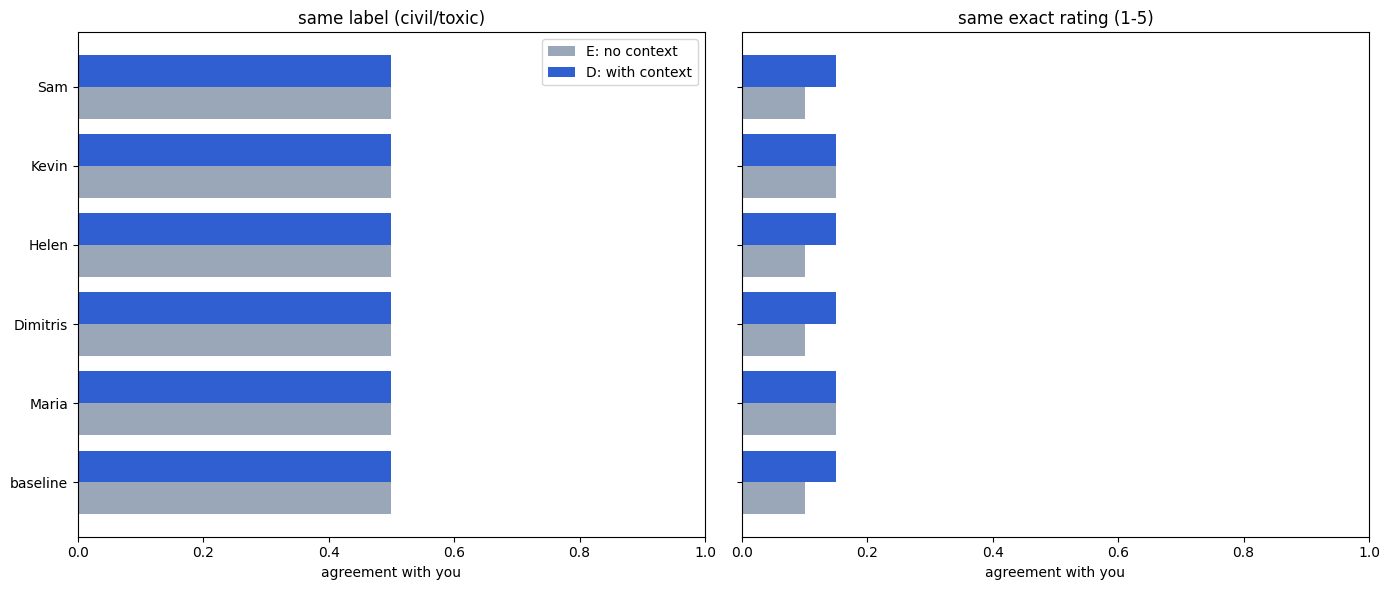

In [68]:
c2 = vs_you("context")
display(c2.round(2))

# E and D side by side + change
side = pd.concat({"E (no context)": c1[["agree_label", "agree_rating"]],
                  "D (context)": c2[["agree_label", "agree_rating"]]}, axis=1)
for m in ["agree_label", "agree_rating"]:
    side[("change D-E", m)] = side[("D (context)", m)] - side[("E (no context)", m)]
display(side.round(2))

fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
y = np.arange(len(ANNOTATOR_ORDER))
for ax, m, title in zip(axs, ["agree_label", "agree_rating"], ["same label (civil/toxic)", "same exact rating (1-5)"]):
    ax.barh(y - 0.2, c1[m].values, 0.4, label="E: no context", color="#9aa7b8")
    ax.barh(y + 0.2, c2[m].values, 0.4, label="D: with context", color="#2f5fd0")
    ax.set_yticks(y); ax.set_yticklabels(ANNOTATOR_ORDER); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.set_xlabel("agreement with you"); ax.set_title(title)
axs[0].legend(); plt.tight_layout(); plt.show()

All annotators again labelled all 20 items toxic, giving 50% label agreement. Exact-rating agreement was 15% for every annotator. Maria and Kevin tied at 15% without context; all five personas tie at 15% with context. The baseline is also at 15% with context, so no persona is closer than the baseline in this condition. These are very small differences: 15% represents three exact matches out of 20.


### Key result: which identity annotates most like you?

In [69]:
def ranking(c):
    r = c.loc[PERSONAS, ["agree_label", "agree_rating", "n_valid"]].copy()
    r = r.sort_values(["agree_label", "agree_rating"], ascending=False)
    r["rank"] = range(1, len(r) + 1)
    return r

for name, c in [("E (no context)", c1), ("D (with context)", c2)]:
    rk = ranking(c)
    best = rk.index[0]
    print(f"\n=== {name}: ranking of personas by agreement with you (label first, then exact rating) ===")
    display(rk.round(2))
    print("Closest:", best, "=", ANNOTATORS[best])
    print("Baseline: label", round(c.loc["baseline", "agree_label"], 2), "| rating", round(c.loc["baseline", "agree_rating"], 2))
    print("Closest persona is closer than the baseline?",
          "label:", bool(rk.iloc[0].agree_label > c.loc["baseline", "agree_label"]),
          "| rating:", bool(rk.iloc[0].agree_rating > c.loc["baseline", "agree_rating"]))


=== E (no context): ranking of personas by agreement with you (label first, then exact rating) ===


,agree_label,agree_rating,n_valid,rank
annotator,,,,
Maria,0.5,0.15,20,1
Kevin,0.5,0.15,20,2
Dimitris,0.5,0.10,20,3
Helen,0.5,0.10,20,4
Sam,0.5,0.10,20,5


Closest: Maria = {'age': 38, 'sex': 'female', 'education_level': "Bachelor's", 'demographic_group': 'Latino', 'current_employment': 'Registered Nurse'}
Baseline: label 0.5 | rating 0.1
Closest persona is closer than the baseline? label: False | rating: True

=== D (with context): ranking of personas by agreement with you (label first, then exact rating) ===


,agree_label,agree_rating,n_valid,rank
annotator,,,,
Maria,0.5,0.15,20,1
Dimitris,0.5,0.15,20,2
Helen,0.5,0.15,20,3
Kevin,0.5,0.15,20,4
Sam,0.5,0.15,20,5


Closest: Maria = {'age': 38, 'sex': 'female', 'education_level': "Bachelor's", 'demographic_group': 'Latino', 'current_employment': 'Registered Nurse'}
Baseline: label 0.5 | rating 0.15
Closest persona is closer than the baseline? label: False | rating: False


The persona that is seemingly closer to me is Maria. However due to the model’s constant toxic labels make its label-agreement scores limited.

### Comparison 3: each annotator, without vs with context (E vs D)

In [70]:
rows = []
for a in ANNOTATOR_ORDER:
    cat, n = agree(L["no_context"][a], L["context"][a])
    num, _ = agree(R["no_context"][a], R["context"][a])
    diff = (R["context"][a] - R["no_context"][a]).dropna()
    rows.append({"annotator": a, "same_label_E_vs_D": cat, "same_rating_E_vs_D": num, "n": n,
                 "mean_rating_E": R["no_context"][a].mean(), "mean_rating_D": R["context"][a].mean(),
                 "mean_shift_D-E": diff.mean(),
                 "items_up": int((diff > 0).sum()), "items_down": int((diff < 0).sum())})
c3 = pd.DataFrame(rows).set_index("annotator")
display(c3.round(2))
print("Baseline vs personas (average of the personas):")
display(pd.DataFrame({"baseline": c3.loc["baseline"], "personas_mean": c3.loc[PERSONAS].mean()}).round(2))
print("You, for reference: mean rating", round(H_RATING.mean(), 2))

,same_label_E_vs_D,same_rating_E_vs_D,n,mean_rating_E,mean_rating_D,mean_shift_D-E,items_up,items_down
annotator,,,,,,,,
baseline,1.0,0.65,20,4.35,5.0,0.65,7,0
Maria,1.0,0.65,20,4.35,5.0,0.65,7,0
Dimitris,1.0,0.60,20,4.30,5.0,0.70,8,0
Helen,1.0,0.60,20,4.30,5.0,0.70,8,0
Kevin,1.0,0.75,20,4.50,5.0,0.50,5,0
Sam,1.0,0.60,20,4.30,5.0,0.70,8,0


Baseline vs personas (average of the personas):


,baseline,personas_mean
same_label_E_vs_D,1.00,1.00
same_rating_E_vs_D,0.65,0.64
n,20.00,20.00
mean_rating_E,4.35,4.35
mean_rating_D,5.00,5.00
mean_shift_D-E,0.65,0.65
items_up,7.00,7.20
items_down,0.00,0.00


You, for reference: mean rating 2.7


Labels did not change for any item because all ratings were in the toxic range in both conditions. Exact ratings changed on 5–8 items per annotator, and every change was upward: no item moved down. Mean ratings rose from 4.30–4.50 without context to 5.00 with context. The baseline rose by 0.65 points. The personas rose by an average of 0.65. My mean was 2.70, so the shift to a mean of 5.00 puts the model ratings farther from my overall rating level, even though exact-rating agreement rose slightly for some annotators. All context ratings are at the top of the scale, so this result also shows a ceiling effect.

### Comparison 4: persona against persona, within each condition

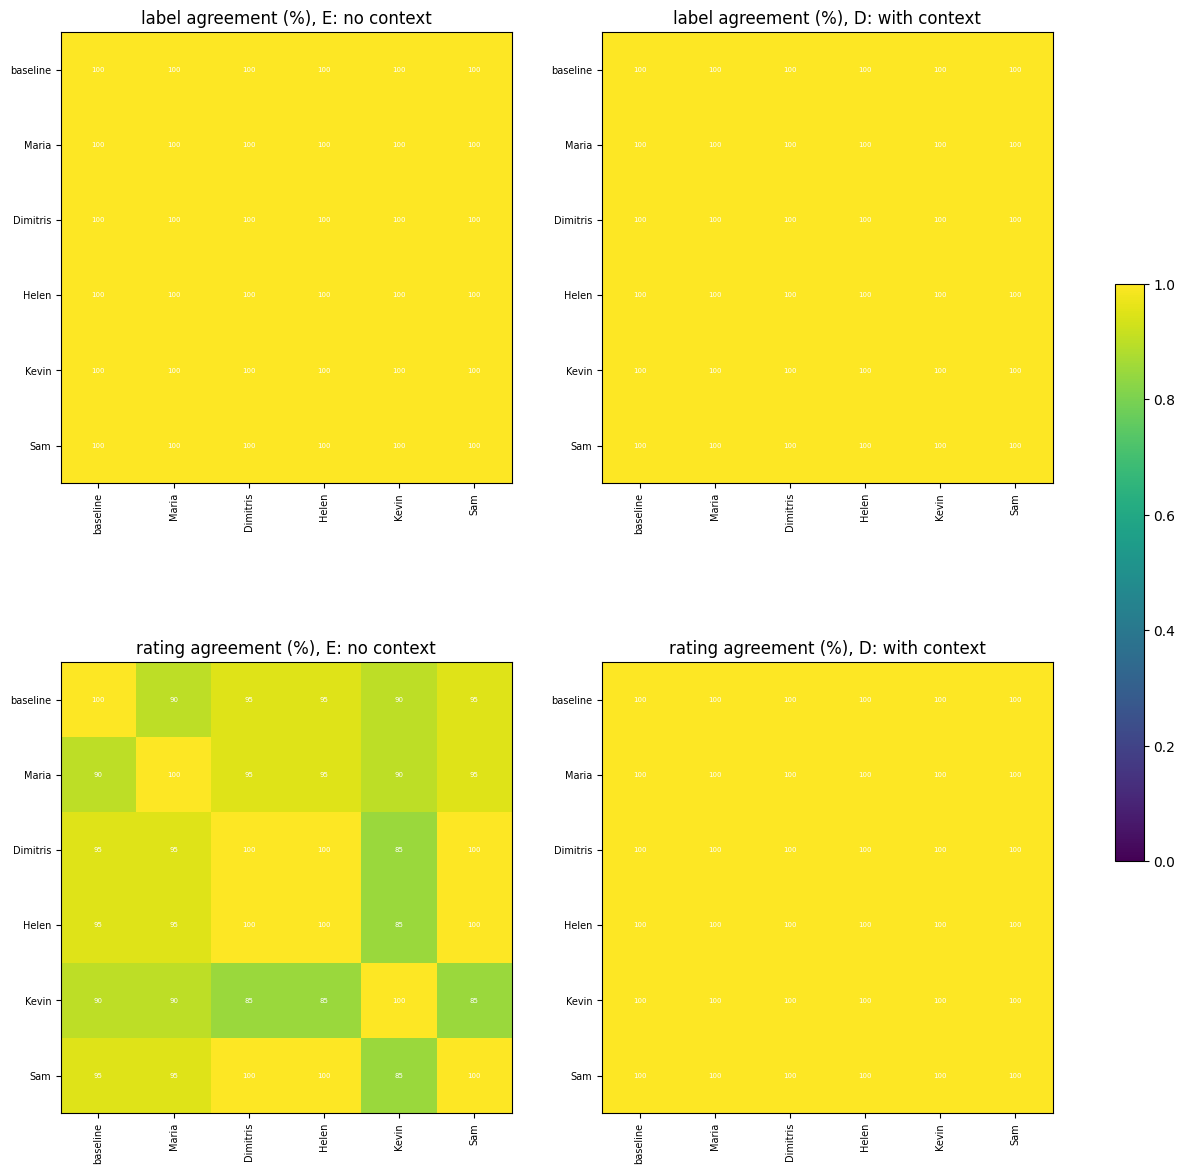

,condition,measure,mean_all_pairs (baseline included),mean_persona_pairs,mean_baseline_vs_persona
0,no_context,label,1.00,1.00,1.00
1,no_context,rating,0.93,0.93,0.93
2,context,label,1.00,1.00,1.00
3,context,rating,1.00,1.00,1.00


In [71]:
def pairwise(cond, kind):
    M = (L if kind == "label" else R)[cond]
    mat = pd.DataFrame(np.nan, index=ANNOTATOR_ORDER, columns=ANNOTATOR_ORDER)
    for a, b in itertools.product(ANNOTATOR_ORDER, repeat=2):
        mat.loc[a, b] = agree(M[a], M[b])[0]
    return mat

PW = {(c, k): pairwise(c, k) for c in ["no_context", "context"] for k in ["label", "rating"]}

def heat(ax, mat, title):
    im = ax.imshow(mat.values.astype(float), vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(mat))); ax.set_xticklabels(mat.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.index, fontsize=7); ax.set_title(title)
    for i in range(len(mat)):
        for j in range(len(mat)):
            ax.text(j, i, f"{mat.values[i, j]*100:.0f}", ha="center", va="center", fontsize=5, color="w")
    return im

fig, axs = plt.subplots(2, 2, figsize=(16, 15))
for r, k in enumerate(["label", "rating"]):
    for c, cond in enumerate(["no_context", "context"]):
        im = heat(axs[r, c], PW[(cond, k)], f"{k} agreement (%), {'E: no context' if cond=='no_context' else 'D: with context'}")
fig.colorbar(im, ax=axs, shrink=0.5); plt.show()

def mean_pairs(mat, names):
    vals = [mat.loc[a, b] for a, b in itertools.combinations(names, 2)]
    return np.nanmean(vals)

summ = []
for cond in ["no_context", "context"]:
    for k in ["label", "rating"]:
        mat = PW[(cond, k)]
        summ.append({"condition": cond, "measure": k,
                     "mean_all_pairs (baseline included)": mean_pairs(mat, ANNOTATOR_ORDER),
                     "mean_persona_pairs": mean_pairs(mat, PERSONAS),
                     "mean_baseline_vs_persona": np.nanmean([mat.loc["baseline", p] for p in PERSONAS])})
display(pd.DataFrame(summ).round(2))

In [72]:
ATTRS = {
    "sex": lambda p: p["sex"],
    "age band": lambda p: "under 30" if p["age"] < 30 else ("30-49" if p["age"] < 50 else "50+"),
    "demographic_group": lambda p: p["demographic_group"],
}
rows = []
for cond in ["no_context", "context"]:
    for k in ["label", "rating"]:
        mat = PW[(cond, k)]
        for name, f in ATTRS.items():
            same, diff = [], []
            for a, b in itertools.combinations(PERSONAS, 2):
                (same if f(ANNOTATORS[a]) == f(ANNOTATORS[b]) else diff).append(mat.loc[a, b])
            rows.append({"condition": cond, "measure": k, "attribute": name,
                         "n_pairs_sharing": len(same),
                         "agree_sharing": np.nanmean(same) if same else np.nan,
                         "agree_differing": np.nanmean(diff) if diff else np.nan})
dim_table = pd.DataFrame(rows)
dim_table["gap (sharing - differing)"] = dim_table.agree_sharing - dim_table.agree_differing
display(dim_table.round(2))
print("Only 10 persona pairs and 1-2 sharing an attribute: read the gaps as hints, not as findings.")

,condition,measure,attribute,n_pairs_sharing,agree_sharing,agree_differing,gap (sharing - differing)
0,no_context,label,sex,2,1.00,1.00,0.00
1,no_context,label,age band,2,1.00,1.00,0.00
2,no_context,label,demographic_group,1,1.00,1.00,0.00
3,no_context,rating,sex,2,0.90,0.94,-0.04
4,no_context,rating,age band,2,0.95,0.92,0.03
5,no_context,rating,demographic_group,1,1.00,0.92,0.08
6,context,label,sex,2,1.00,1.00,0.00
7,context,label,age band,2,1.00,1.00,0.00
8,context,label,demographic_group,1,1.00,1.00,0.00
9,context,rating,sex,2,1.00,1.00,0.00


Only 10 persona pairs and 1-2 sharing an attribute: read the gaps as hints, not as findings.


Label agreement was 100% in both conditions because everyone always used the toxic label. Mean pairwise exact-rating agreement was 93% without context and 100% with context. With context, every model annotator gave every item a rating of 5. Without context, ratings varied slightly but were still mostly 4 or 5. The attribute analysis does not provide strong evidence about which dimension matters most: without context, demographic-group pairs had the largest apparent rating-agreement gap (8 percentage points), but only one persona pair shared that value. The gaps were zero with context. With five personas and very few matching-attribute pairs, these differences should be treated as descriptive hints, not evidence that demographic group, age, or sex caused the agreement pattern.

## G. Explanations

The model underperformed as an annotator in this experiment. Without context, all annotators labelled every item toxic, despite my ratings being evenly split between civil and toxic. Their 50% label agreement therefore matches what a constant “toxic” predictor would achieve on my sample. Exact-rating agreement was also low, at 10–15%.

Adding discussion context did not improve the model’s ability to distinguish civil from toxic comments: every label remained toxic. Instead, the context pushed all ratings to 5, the most toxic rating. This made the annotators agree perfectly with one another, but that agreement reflects identical, extreme outputs rather than better alignment with my ratings. Their mean rating moved farther from mine.

Persona identity had little visible effect. The personas and the baseline produced the same labels, and their exact ratings were highly similar. The small differences in agreement with my ratings amount to only one item and do not support a reliable ranking of identities or a conclusion about which demographic dimension matters most.

These results are limited to 20 comments, one small model, and one generated discussion per comment. Each item changes an agreement score by five percentage points, and the constant toxic predictions make the label results especially limited. The closest persona does not mean that I share that identity. Overall, this setup did not produce dependable persona-based annotations, and the discussion context made the ratings more extreme without making them more useful.

A stronger model might follow the rating instructions and quote valid evidence more consistently, reducing invalid evidence and avoiding the tendency to rate every comment as highly toxic. Its ratings might also vary more across comments and personas. However, due to limited time and resources, I wasn't able to explore it.